In [10]:


!cd /kaggle/working && git clone https://github.com/maudzung/SFA3D.git

Cloning into 'SFA3D'...
remote: Enumerating objects: 300, done.
remote: Counting objects: 100% (92/92), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 300 (delta 63), reused 49 (delta 49), pack-reused 208 (from 1)
Receiving objects: 100% (300/300), 45.48 MiB | 26.81 MiB/s, done.
Resolving deltas: 100% (153/153), done.


In [11]:
import sys
import os

# ============================================================
# SFA3D ROOT
# ============================================================

SFA3D_ROOT = "/kaggle/working/SFA3D"


# Add SFA3D to Python path
if SFA3D_ROOT not in sys.path:
    sys.path.insert(0, SFA3D_ROOT)

print("SFA3D ROOT:")
print(SFA3D_ROOT)

print("\nSFA3D contents:")
print(os.listdir(SFA3D_ROOT))

SFA3D ROOT:
/kaggle/working/SFA3D

SFA3D contents:
['Technical_details.md', 'checkpoints', 'dataset', 'sfa', 'README.md', '.gitignore', 'requirements.txt', 'LICENSE', '.git']


In [12]:
import os
import cv2
import torch
import numpy as np

# ============================================================
# SFA3D imports
# ============================================================

from sfa.config import kitti_config as cnf
from sfa.data_process.kitti_bev_utils import makeBEVMap
from sfa.data_process.kitti_dataset import get_filtered_lidar
from sfa.models.fpn_resnet import get_pose_net
from sfa.utils.evaluation_utils import decode
from sfa.utils.torch_utils import _sigmoid
from sfa.utils.evaluation_utils import (
    decode,
    post_processing,
    convert_det_to_real_values
)
from sfa.utils.evaluation_utils import draw_predictions
import matplotlib.pyplot as plt


In [13]:
# ============================================================
# Configuration
# ============================================================

DATA_ROOT = "/kaggle/input/datasets/garymk/kitti-3d-object-detection-dataset"

# ------------------------------------------------------------
# SFA3D pretrained model
# ------------------------------------------------------------

CHECKPOINT = (
    "/kaggle/working/SFA3D/"
    "checkpoints/fpn_resnet_18/"
    "fpn_resnet_18_epoch_300.pth"
)

# ------------------------------------------------------------
# KITTI sample
# ------------------------------------------------------------

SAMPLE_ID = "000008"

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


In [5]:
!pip install open3d -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 3.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 96.8 MB/s eta 0:00:00:00:0100:01


In [6]:
import numpy as np
import open3d as o3d

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [14]:
def get_box_corners(box):
    """
    Convert one SFA3D LiDAR box into its 8 3D corners.

    Input:
        box = [class_id, x, y, z, h, w, l, yaw]

    Coordinates:
        x = forward
        y = left/right
        z = vertical
    """

    class_id, x, y, z, h, w, l, yaw = box

    # --------------------------------------------------------
    # Half dimensions
    # --------------------------------------------------------

    half_l = l / 2.0
    half_w = w / 2.0
    half_h = h / 2.0

    # --------------------------------------------------------
    # Box corners BEFORE rotation
    #
    # x direction = length
    # y direction = width
    # z direction = height
    # --------------------------------------------------------

    corners = np.array([
        [ half_l,  half_w,  half_h],
        [ half_l, -half_w,  half_h],
        [-half_l, -half_w,  half_h],
        [-half_l,  half_w,  half_h],

        [ half_l,  half_w, -half_h],
        [ half_l, -half_w, -half_h],
        [-half_l, -half_w, -half_h],
        [-half_l,  half_w, -half_h]
    ])

    # --------------------------------------------------------
    # Rotation around Z axis
    # --------------------------------------------------------

    cos_yaw = np.cos(yaw)
    sin_yaw = np.sin(yaw)

    rotation = np.array([
        [cos_yaw, -sin_yaw, 0],
        [sin_yaw,  cos_yaw, 0],
        [0,       0,        1]
    ])

    # Rotate corners
    corners = corners @ rotation.T

    # --------------------------------------------------------
    # Move box to its center position
    # --------------------------------------------------------

    corners[:, 0] += x
    corners[:, 1] += y
    corners[:, 2] += z

    return corners

In [15]:
def create_box_lines(corners):
    """
    Create the 12 edges of a 3D bounding box.
    """

    lines = [
        # Bottom rectangle
        [0, 1],
        [1, 2],
        [2, 3],
        [3, 0],

        # Top rectangle
        [4, 5],
        [5, 6],
        [6, 7],
        [7, 4],

        # Vertical edges
        [0, 4],
        [1, 5],
        [2, 6],
        [3, 7]
    ]

    line_set = o3d.geometry.LineSet()

    line_set.points = o3d.utility.Vector3dVector(
        corners
    )

    line_set.lines = o3d.utility.Vector2iVector(
        lines
    )

    return line_set

In [16]:
def create_point_cloud(points):
    """
    Convert KITTI LiDAR points into an Open3D point cloud.
    """

    # Only XYZ
    xyz = points[:, :3]

    point_cloud = o3d.geometry.PointCloud()

    point_cloud.points = o3d.utility.Vector3dVector(
        xyz
    )

    return point_cloud

In [10]:
!pip install plotly -q

In [17]:
import numpy as np
import plotly.graph_objects as go


def visualize_predictions_kaggle(points, lidar_boxes):

    fig = go.Figure()

    # ========================================================
    # LiDAR points
    # ========================================================

    xyz = points[:, :3]

    # To make the visualization faster,
    # randomly sample points if there are too many.
    max_points = 30000

    if len(xyz) > max_points:

        indices = np.random.choice(
            len(xyz),
            max_points,
            replace=False
        )

        xyz = xyz[indices]

    fig.add_trace(
        go.Scatter3d(
            x=xyz[:, 0],
            y=xyz[:, 1],
            z=xyz[:, 2],
            mode="markers",
            marker=dict(
                size=1,
                opacity=0.5
            ),
            name="LiDAR"
        )
    )

    # ========================================================
    # Draw predicted 3D boxes
    # ========================================================

    for i, box in enumerate(lidar_boxes):

        corners = get_box_corners(box)

        # The 12 edges of a 3D box
        lines = [
            (0, 1),
            (1, 2),
            (2, 3),
            (3, 0),

            (4, 5),
            (5, 6),
            (6, 7),
            (7, 4),

            (0, 4),
            (1, 5),
            (2, 6),
            (3, 7)
        ]

        # Draw every edge
        for start, end in lines:

            fig.add_trace(
                go.Scatter3d(
                    x=[
                        corners[start, 0],
                        corners[end, 0]
                    ],
                    y=[
                        corners[start, 1],
                        corners[end, 1]
                    ],
                    z=[
                        corners[start, 2],
                        corners[end, 2]
                    ],
                    mode="lines",
                    line=dict(
                        width=5
                    ),
                    showlegend=False
                )
            )

        # ----------------------------------------------------
        # Add box number at its center
        # ----------------------------------------------------

        class_id, x, y, z, h, w, l, yaw = box

        fig.add_trace(
            go.Scatter3d(
                x=[x],
                y=[y],
                z=[z + h / 2 + 0.3],
                mode="text",
                text=[f"Box {i}"],
                textposition="top center",
                showlegend=False
            )
        )

    # ========================================================
    # LiDAR coordinate system
    # ========================================================

    fig.add_trace(
        go.Scatter3d(
            x=[0, 5],
            y=[0, 0],
            z=[0, 0],
            mode="lines+text",
            text=["", "X"],
            line=dict(width=5),
            name="X axis"
        )
    )

    fig.add_trace(
        go.Scatter3d(
            x=[0, 0],
            y=[0, 5],
            z=[0, 0],
            mode="lines+text",
            text=["", "Y"],
            line=dict(width=5),
            name="Y axis"
        )
    )

    fig.add_trace(
        go.Scatter3d(
            x=[0, 0],
            y=[0, 0],
            z=[0, 5],
            mode="lines+text",
            text=["", "Z"],
            line=dict(width=5),
            name="Z axis"
        )
    )

    # ========================================================
    # Layout
    # ========================================================

    fig.update_layout(
        title="SFA3D Predictions — KITTI LiDAR",
        scene=dict(
            xaxis_title="X — Forward",
            yaxis_title="Y — Left / Right",
            zaxis_title="Z — Up / Down",
            aspectmode="data"
        ),
        width=1000,
        height=800
    )

    fig.show()

In [18]:

# ============================================================
# Load KITTI labels
# ============================================================

def load_kitti_labels(sample_id):

    label_path = os.path.join(
        DATA_ROOT,
        "training",
        "label_2",
        sample_id + ".txt"
    )

    with open(label_path, "r") as f:
        lines = f.readlines()

    return lines

# ============================================================
# Load LiDAR
# ============================================================
def load_lidar(sample_id):

    lidar_path = os.path.join(
        DATA_ROOT,
        "training",
        "velodyne",
        sample_id + ".bin"
    )

    points = np.fromfile(
        lidar_path,
        dtype=np.float32
    )

    points = points.reshape(-1, 4)

    return points


# ============================================================
# Load image
# ============================================================

def load_image(sample_id):

    image_path = os.path.join(
        DATA_ROOT,
        "training",
        "image_2",
        sample_id + ".png"
    )

    image = cv2.imread(image_path)

    return image


# ============================================================
# Create model
# ============================================================

def create_model():

    heads = {
    'hm_cen': 3,
    'cen_offset': 2,
    'direction': 2,
    'z_coor': 1,
    'dim': 3
    }

    model = get_pose_net(
        num_layers=18,
        heads=heads,
        head_conv=64,
        imagenet_pretrained=False
    )

    model = model.to(DEVICE)

    checkpoint = torch.load(
        CHECKPOINT,
        map_location=DEVICE
    )

    if "model_state_dict" in checkpoint:

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

    else:

        model.load_state_dict(
            checkpoint
        )

    model.eval()

    return model


# ============================================================
# Prepare BEV
# ============================================================

def prepare_bev(points):

    # --------------------------------------------------------
    # SFA3D original LiDAR filtering
    # --------------------------------------------------------

    points = get_filtered_lidar(
        points,
        cnf.boundary
    )

    print(
        "Filtered LiDAR shape:",
        points.shape
    )

    # --------------------------------------------------------
    # SFA3D original BEV map
    # --------------------------------------------------------

    bev_map = makeBEVMap(
        points,
        cnf.boundary
    )

    print(
        "Original BEV shape:",
        bev_map.shape
    )

    # --------------------------------------------------------
    # Keep a copy for visualization
    # --------------------------------------------------------

    bev_visual = (
        bev_map
        .transpose(1, 2, 0)
        * 255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # BEV input for model
    # --------------------------------------------------------

    bev_tensor = torch.from_numpy(
        bev_map
    )

    bev_tensor = bev_tensor.unsqueeze(0)

    bev_tensor = bev_tensor.to(
        DEVICE
    ).float()

    return bev_tensor, bev_visual


# ============================================================
# Run inference
# ============================================================

def detect(model, bev):

    with torch.no_grad():

        outputs = model(bev)

        # Heatmap logits -> probabilities
        hm_cen = _sigmoid(outputs['hm_cen'])

        # Decode the top K predictions
        detections = decode(
            hm_cen,
            outputs['cen_offset'],
            outputs['direction'],
            outputs['z_coor'],
            outputs['dim'],
            K=40
        )

    # Convert PyTorch tensor -> NumPy
    detections = detections.cpu().numpy().astype(np.float32)

    # Official SFA3D post-processing
    detections = post_processing(
        detections,
        num_classes=3,
        down_ratio=4,
        peak_thresh=0.20
    )

    return detections

def convert_to_lidar_boxes(detections):

    lidar_boxes = convert_det_to_real_values(
        detections,
        num_classes=3
    )

    return lidar_boxes
# ============================================================
# Filter detections
# ============================================================
def filter_detections(detections, threshold=0.2):

    detections = detections[0].detach().cpu()

    # score is column 0
    scores = detections[:, 0]

    mask = scores >= threshold

    detections = detections[mask]

    return detections

# ============================================================
# Convert SFA3D boxes for Vedo
# ============================================================



Filtered LiDAR shape: (59937, 4)
Original BEV shape: (3, 608, 608)


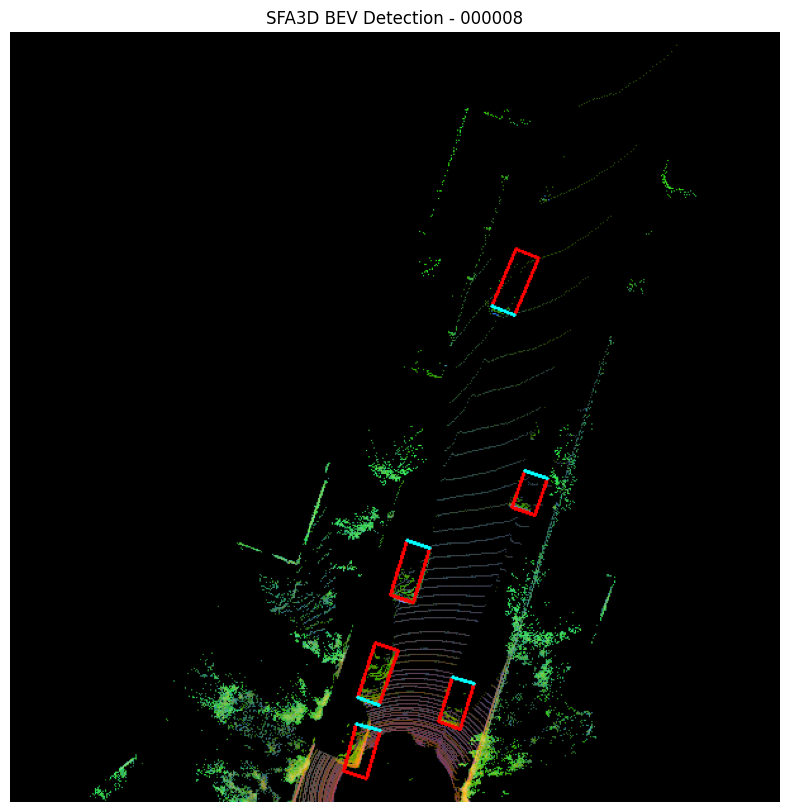

In [19]:
def main():

    # Load LiDAR
    points = load_lidar(SAMPLE_ID)

    # Load image
    image = load_image(SAMPLE_ID)

    # Create SFA3D BEV input
    bev, bev_visual = prepare_bev(points)

    # Load model
    model = create_model()

    # Run detection
    detections = detect(
        model,
        bev
    )

    # Convert detections to real LiDAR coordinates
    lidar_boxes = convert_to_lidar_boxes(
        detections[0]
    )

    # --------------------------------------------------------
    # Create 2D Bird's-Eye View visualization
    # --------------------------------------------------------

    # ============================================================
    # SFA3D BEV visualization
    # ============================================================
    
    bev_image = draw_predictions(
        bev_visual.copy(),
        detections[0].copy(),
        3
    )
    
    # ============================================================
    # Rotate exactly like original test.py
    # ============================================================
    
    bev_image = cv2.rotate(
        bev_image,
        cv2.ROTATE_180
    )
    
    # ============================================================
    # Display
    # ============================================================
    
    plt.figure(
        figsize=(10, 10)
    )
    
    plt.imshow(
        cv2.cvtColor(
            bev_image,
            cv2.COLOR_BGR2RGB
        )
    )
    
    plt.title(
        f"SFA3D BEV Detection - {SAMPLE_ID}"
    )
    
    plt.axis("off")
    
    plt.show()


if __name__ == "__main__":
    main()

In [13]:
import inspect
from sfa.data_process.kitti_data_utils import get_filtered_lidar

print(inspect.getsource(get_filtered_lidar))

def get_filtered_lidar(lidar, boundary, labels=None):
    minX = boundary['minX']
    maxX = boundary['maxX']
    minY = boundary['minY']
    maxY = boundary['maxY']
    minZ = boundary['minZ']
    maxZ = boundary['maxZ']

    # Remove the point out of range x,y,z
    mask = np.where((lidar[:, 0] >= minX) & (lidar[:, 0] <= maxX) &
                    (lidar[:, 1] >= minY) & (lidar[:, 1] <= maxY) &
                    (lidar[:, 2] >= minZ) & (lidar[:, 2] <= maxZ))
    lidar = lidar[mask]
    lidar[:, 2] = lidar[:, 2] - minZ

    if labels is not None:
        label_x = (labels[:, 1] >= minX) & (labels[:, 1] < maxX)
        label_y = (labels[:, 2] >= minY) & (labels[:, 2] < maxY)
        label_z = (labels[:, 3] >= minZ) & (labels[:, 3] < maxZ)
        mask_label = label_x & label_y & label_z
        labels = labels[mask_label]
        return lidar, labels
    else:
        return lidar



In [6]:
import inspect

print(inspect.getsource(makeBEVMap))

def makeBEVMap(PointCloud_, boundary):
    Height = cnf.BEV_HEIGHT + 1
    Width = cnf.BEV_WIDTH + 1

    # Discretize Feature Map
    PointCloud = np.copy(PointCloud_)
    PointCloud[:, 0] = np.int_(np.floor(PointCloud[:, 0] / cnf.DISCRETIZATION))
    PointCloud[:, 1] = np.int_(np.floor(PointCloud[:, 1] / cnf.DISCRETIZATION) + Width / 2)

    # sort-3times
    sorted_indices = np.lexsort((-PointCloud[:, 2], PointCloud[:, 1], PointCloud[:, 0]))
    PointCloud = PointCloud[sorted_indices]
    _, unique_indices, unique_counts = np.unique(PointCloud[:, 0:2], axis=0, return_index=True, return_counts=True)
    PointCloud_top = PointCloud[unique_indices]

    # Height Map, Intensity Map & Density Map
    heightMap = np.zeros((Height, Width))
    intensityMap = np.zeros((Height, Width))
    densityMap = np.zeros((Height, Width))

    # some important problem is image coordinate is (y,x), not (x,y)
    max_height = float(np.abs(boundary['maxZ'] - boundary['minZ']))
    heightMap[np.int_(PointC

In [23]:
print(inspect.getsource(decode))


def decode(hm_cen, cen_offset, direction, z_coor, dim, K=40):
    batch_size, num_classes, height, width = hm_cen.size()

    hm_cen = _nms(hm_cen)
    scores, inds, clses, ys, xs = _topk(hm_cen, K=K)
    if cen_offset is not None:
        cen_offset = _transpose_and_gather_feat(cen_offset, inds)
        cen_offset = cen_offset.view(batch_size, K, 2)
        xs = xs.view(batch_size, K, 1) + cen_offset[:, :, 0:1]
        ys = ys.view(batch_size, K, 1) + cen_offset[:, :, 1:2]
    else:
        xs = xs.view(batch_size, K, 1) + 0.5
        ys = ys.view(batch_size, K, 1) + 0.5

    direction = _transpose_and_gather_feat(direction, inds)
    direction = direction.view(batch_size, K, 2)
    z_coor = _transpose_and_gather_feat(z_coor, inds)
    z_coor = z_coor.view(batch_size, K, 1)
    dim = _transpose_and_gather_feat(dim, inds)
    dim = dim.view(batch_size, K, 3)
    clses = clses.view(batch_size, K, 1).float()
    scores = scores.view(batch_size, K, 1)

    # (scores x 1, ys x 1, xs x 1, z

In [21]:
print(inspect.getsource(convert_to_lidar_boxes))



def convert_to_lidar_boxes(detections):

    lidar_boxes = convert_det_to_real_values(
        detections,
        num_classes=3
    )

    return lidar_boxes



In [22]:
print(inspect.getsource(convert_det_to_real_values))



def convert_det_to_real_values(detections, num_classes=3):
    kitti_dets = []
    for cls_id in range(num_classes):
        if len(detections[cls_id]) > 0:
            for det in detections[cls_id]:
                # (scores-0:1, x-1:2, y-2:3, z-3:4, dim-4:7, yaw-7:8)
                _score, _x, _y, _z, _h, _w, _l, _yaw = det
                _yaw = -_yaw
                x = _y / cnf.BEV_HEIGHT * cnf.bound_size_x + cnf.boundary['minX']
                y = _x / cnf.BEV_WIDTH * cnf.bound_size_y + cnf.boundary['minY']
                z = _z + cnf.boundary['minZ']
                w = _w / cnf.BEV_WIDTH * cnf.bound_size_y
                l = _l / cnf.BEV_HEIGHT * cnf.bound_size_x

                kitti_dets.append([cls_id, x, y, z, _h, w, l, _yaw])

    return np.array(kitti_dets)



In [ ]:
cnf